# GDP per Capita and International Tourist Arrivals in Sri Lanka

## 1. Problem Definition

How is GDP per capita related to international tourist arrivals in Sri Lanka?

In this project, we aim to explore the relationship between Sri Lanka's economic performance and international tourism by analyzing GDP per capita and tourist arrival data over time.

The project focuses on managing, cleaning, transforming, and integrating datasets from different sources to produce a high-quality dataset suitable for further analysis.

## 2. Data

The data is collected from two different sources:

There are two main datasets used in this project:

**Dataset 1: GDP per Capita Data**
- Source: World Development Indicators (DataHub).
- File name: `GDP_data.csv`
- Contains GDP per capita information over different years.
- Used to examine Sri Lanka's economic performance over time.

**Dataset 2: International Tourist Arrivals Data**
- Source: Sri Lankan tourism statistics.
- File name: `tourist-arrivals-by-market-2026-10-15.csv`
- Contains information about international tourist arrivals by source market.
- Used to examine tourism trends and patterns in Sri Lanka.

## 3. Objectives

The main objective of this project is to clean, integrate, and prepare GDP per capita and international tourist arrivals datasets to explore their relationship in Sri Lanka.

The specific objectives are:

1. Identify and handle missing values in both datasets.
2. Detect and handle duplicate records and outliers.
3. Correct inconsistent data types and formats.
4. Transform and aggregate data where necessary.
5. Integrate both datasets using a common time variable (year and Country).
6. Apply appropriate data preparation techniques.
7. Produce a final clean and structured dataset for further analysis.

## 4. Data Management Process

The following data management steps will be performed:

1. Import the required libraries.
2. Load both datasets.
3. Understand and inspect the datasets.
4. Identify and handle missing values.
5. Detect and handle outliers.
6. Correct data types and inconsistent formats.
7. Transform and prepare the datasets.
8. Integrate the datasets.
9. Validate the final integrated dataset.
10. Export the cleaned datasets and final integrated dataset.

## 5. Expected Outcome

The expected outcome is a clean, structured, and integrated dataset containing GDP per capita and international tourist arrival information for Sri Lanka.

This dataset will be suitable for further statistical analysis to explore the relationship between economic performance and international tourism.

In [74]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# For the Standardized
from sklearn.preprocessing import StandardScaler
import os


In [75]:
# import datasets
gdp = pd.read_csv("GDP_data.csv")
tourist = pd.read_csv("tourist-arrivals-by-market-2026-10-15.csv")

# GDP data

In [76]:
# get first 5 data from GDP csv file
gdp.head()

,Country Name,Country Code,Year,Value
0,Aruba,ABW,1986,6767.559229
1,Aruba,ABW,1987,8244.045660
2,Aruba,ABW,1988,10056.261393
3,Aruba,ABW,1989,11507.217151
4,Aruba,ABW,1990,12187.536361


In [77]:
# number of columns and rows in GDP
gdp.shape

(14562, 4)

In [78]:
# Display the structure, column names, data types, and non-null values of the GDP dataset.
gdp.info()

<class 'pandas.DataFrame'>
RangeIndex: 14562 entries, 0 to 14561
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  14562 non-null  str    
 1   Country Code  14562 non-null  str    
 2   Year          14562 non-null  int64  
 3   Value         14562 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 455.2 KB


In [79]:
# Data types of GDP
gdp.dtypes

Country Name        str
Country Code        str
Year              int64
Value           float64
dtype: object

In [80]:
# Numerical summary of the GDP
gdp.describe()

,Year,Value
count,14562.000000,14562.000000
mean,1994.832509,8701.348431
std,18.109486,17594.855912
min,1960.000000,11.801322
25%,1980.000000,583.829426
50%,1996.000000,1938.628948
75%,2010.000000,8045.440559
max,2024.000000,288001.433369


In [81]:
# Number of missing values in GDP
gdp.isna().sum()

Country Name    0
Country Code    0
Year            0
Value           0
dtype: int64

In [82]:
# Number of duplicates in GDP
gdp.duplicated().sum()

np.int64(0)

# Tourist dataset

In [83]:
# Show the first 5 rows in tourist csv file
tourist.head()

,date,indicator,value,unit,geography,status,source
0,2011-01-01,All countries,74197,arrivals,LK,unflagged,sltda-asr-2011
1,2011-02-01,All countries,65797,arrivals,LK,unflagged,sltda-asr-2011
2,2011-03-01,All countries,75130,arrivals,LK,unflagged,sltda-asr-2011
3,2011-04-01,All countries,63835,arrivals,LK,unflagged,sltda-asr-2011
4,2011-05-01,All countries,48943,arrivals,LK,unflagged,sltda-asr-2011


In [84]:
# Number of columns and rows in the tourist dataframe
tourist.shape

(5772, 7)

In [85]:
# Display the structure, column names, data types, and non-null values of the tourist dataset
tourist.info()

<class 'pandas.DataFrame'>
RangeIndex: 5772 entries, 0 to 5771
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   date       5772 non-null   str  
 1   indicator  5772 non-null   str  
 2   value      5772 non-null   int64
 3   unit       5772 non-null   str  
 4   geography  5772 non-null   str  
 5   status     5772 non-null   str  
 6   source     5772 non-null   str  
dtypes: int64(1), str(6)
memory usage: 315.8 KB


In [86]:
# Data types of tourist dataset
tourist.dtypes

date           str
indicator      str
value        int64
unit           str
geography      str
status         str
source         str
dtype: object

In [87]:
# find any missing values in tourist DataFrame
tourist.isna().sum()

date         0
indicator    0
value        0
unit         0
geography    0
status       0
source       0
dtype: int64

In [88]:
# Number of duplicates in tourist DataFrame
tourist.duplicated().sum()

np.int64(0)

# Data cleaning
The GDP and tourism datasets were checked for missing values using Pandas.

The inspection confirmed that there were no missing values in the datasets. Therefore, no missing-value imputation or removal was required.

The data types of the columns were inspected to ensure they were appropriate for further processing. The Year column was converted to an integer data type where necessary.

Column names were renamed to meaningful labels to improve readability and understanding.

In [89]:
# copy of tourist and gdp
tourist_clean = tourist.copy()
gdp_clean = gdp.copy()

In [90]:
#remove the extra spaces from the columns name
gdp_clean.columns = gdp_clean.columns.str.strip()
tourist_clean.columns = tourist_clean.columns.str.strip()

In [91]:
# remove the extra spaces values from the columns
gdp_clean["Country Name"] = gdp_clean["Country Name"].astype(str).str.strip()
gdp_clean["Country Code"] = gdp_clean["Country Code"].astype(str).str.strip()

tourist_clean["indicator"] = tourist_clean["indicator"].astype(str).str.strip()
tourist_clean["unit"] = tourist_clean["unit"].astype(str).str.strip()
tourist_clean["geography"] = tourist_clean["geography"].astype(str).str.strip()
tourist_clean["status"] = tourist_clean["status"].astype(str).str.strip()

In [92]:
# show the 2 rows in GDP
gdp_clean.head(2)

,Country Name,Country Code,Year,Value
0,Aruba,ABW,1986,6767.559229
1,Aruba,ABW,1987,8244.045660


In [93]:
# show first two row in tourist data
tourist_clean.head(2)

,date,indicator,value,unit,geography,status,source
0,2011-01-01,All countries,74197,arrivals,LK,unflagged,sltda-asr-2011
1,2011-02-01,All countries,65797,arrivals,LK,unflagged,sltda-asr-2011


In [94]:
# values convert to the numeric
gdp_clean["Year"] = pd.to_numeric(gdp_clean["Year"], errors="coerce")
gdp_clean["Value"] = pd.to_numeric(gdp_clean["Value"], errors="coerce")

tourist_clean["value"] = pd.to_numeric(tourist_clean["value"], errors="coerce")

In [95]:
# conert to datatime
tourist_clean["date"] = pd.to_datetime(tourist_clean["date"], errors="coerce")

In [96]:
gdp_clean = gdp_clean.dropna(subset=["Country Name", "Year", "Value"])
tourist_clean = tourist_clean.dropna(subset=["date", "indicator", "value"])

In [97]:
# year variable convert to int and  reanem columns names
gdp_clean["Year"] = gdp_clean["Year"].astype(int)
gdp_clean = gdp_clean.rename(columns={"Country Name":"Country"})
gdp_clean = gdp_clean.rename(columns={"Value": "GDP_Per_Capita"})

In [98]:
# date column get separately year and variable convert to int and  rename columns names
tourist_clean["Year"] = tourist_clean["date"].dt.year.astype(int)
tourist_clean = tourist_clean.rename(columns={"indicator":"Country"})
tourist_clean = tourist_clean.rename(columns={"value":"Tourist Arrival"})

In [99]:
# find any zero values in the GDP DataFrame
(gdp_clean == 0).sum()

Country           0
Country Code      0
Year              0
GDP_Per_Capita    0
dtype: int64

In [100]:
# Find any zero values in the tourist DataFrame
(tourist_clean == 0).sum()

date                 0
Country              0
Tourist Arrival    302
unit                 0
geography            0
status               0
source               0
Year                 0
dtype: int64

In [101]:
# Tourist arrival counts zero
print(tourist_clean[tourist_clean["Tourist Arrival"] == 0].shape)
tourist_clean[tourist_clean["Tourist Arrival"] == 0].head(20)
# I think affect COVID 19 in this time period

(302, 8)


,date,Country,Tourist Arrival,unit,geography,status,source,Year
111,2020-04-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
112,2020-05-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
113,2020-06-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
114,2020-07-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
115,2020-08-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
116,2020-09-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
117,2020-10-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
118,2020-11-01,All countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
300,2020-04-01,All other countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020
301,2020-05-01,All other countries,0,arrivals,LK,unflagged,sltda-markets-2020,2020


In [102]:
gdp_clean.head()

,Country,Country Code,Year,GDP_Per_Capita
0,Aruba,ABW,1986,6767.559229
1,Aruba,ABW,1987,8244.045660
2,Aruba,ABW,1988,10056.261393
3,Aruba,ABW,1989,11507.217151
4,Aruba,ABW,1990,12187.536361


In [103]:
tourist_clean.head()

,date,Country,Tourist Arrival,unit,geography,status,source,Year
0,2011-01-01,All countries,74197,arrivals,LK,unflagged,sltda-asr-2011,2011
1,2011-02-01,All countries,65797,arrivals,LK,unflagged,sltda-asr-2011,2011
2,2011-03-01,All countries,75130,arrivals,LK,unflagged,sltda-asr-2011,2011
3,2011-04-01,All countries,63835,arrivals,LK,unflagged,sltda-asr-2011,2011
4,2011-05-01,All countries,48943,arrivals,LK,unflagged,sltda-asr-2011,2011


In [104]:
# Shape of the GDP and Tourist
print("Shape of the GDP :",gdp_clean.shape,"\nShape of the tourist:",tourist_clean.shape)

Shape of the GDP : (14562, 4) 
Shape of the tourist: (5772, 8)


## Identify the Outliers
The Interquartile Range (IQR) method was used to identify potential outliers in both the GDP and tourism datasets.

The IQR was calculated as the difference between the third quartile (Q3) and the first quartile (Q1).

The lower and upper bounds were calculated using:

* Lower Bound = Q1 − 1.5 * IQR
* Upper Bound = Q3 + 1.5 * IQR

Observations falling outside these bounds were identified as potential outliers. Histograms and box plots were also used to examine the distributions of the numerical variables.

The identified outliers were inspected rather than automatically removed, because extreme GDP and tourist-arrival values may represent genuine observations.

In [105]:
# GDP clean

# Identify the Q1,Q2,Q3 and Inter Quartile Range
Q1,Q2,Q3 = gdp_clean['GDP_Per_Capita'].quantile([0.25,0.5,0.75])
IQR = Q3 - Q1
lower,upper = Q1 - 1.5*IQR ,Q3 + 1.5*IQR

# number of outliers
gdp_outliers = gdp_clean[(gdp_clean['GDP_Per_Capita'] < lower) | (gdp_clean['GDP_Per_Capita'] > upper)]

# Mean,median,Standard deviation
# Precenatage of outliers
print(f"Number of Outliers : {len(gdp_outliers)} \n\nMedian : {Q2:.2f} \nMean : {np.mean(gdp_clean['GDP_Per_Capita']):.2f} \nStandard Deviation : {np.std(gdp_clean['GDP_Per_Capita']):.2f} \n\nPrecentage of Outliers : {(len(gdp_outliers)/len(gdp_clean))*100:.2f}%")
gdp_outliers.reset_index(drop=True)

Number of Outliers : 1987 

Median : 1938.63 
Mean : 8701.35 
Standard Deviation : 17594.25 

Precentage of Outliers : 13.65%


,Country,Country Code,Year,GDP_Per_Capita
0,Aruba,ABW,2000,20681.023027
1,Aruba,ABW,2001,20740.132583
2,Aruba,ABW,2002,21307.248251
3,Aruba,ABW,2003,21949.485996
4,Aruba,ABW,2004,23700.631990
...,...,...,...,...
1982,Virgin Islands (U.S.),VIR,2018,36663.208755
1983,Virgin Islands (U.S.),VIR,2019,38633.529892
1984,Virgin Islands (U.S.),VIR,2020,39787.374165
1985,Virgin Islands (U.S.),VIR,2021,42571.077737


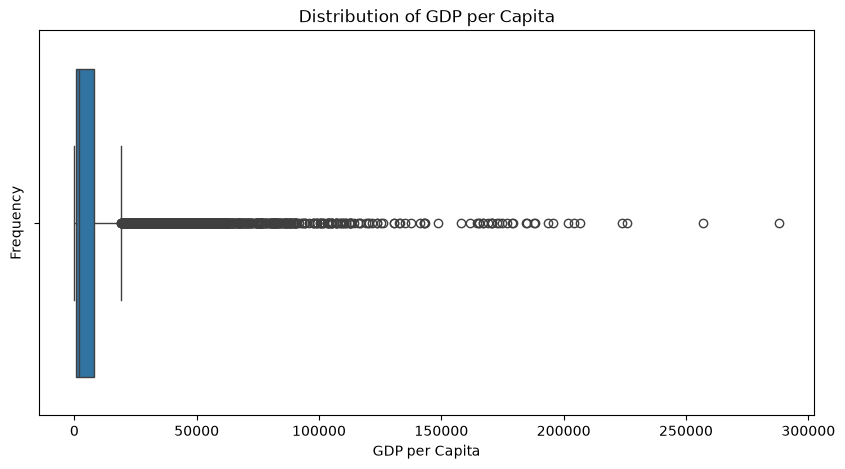

In [106]:
# Boxplot for the Distributionof GDP per Capita
plt.figure(figsize=(10, 5))
sns.boxplot(x=gdp_clean['GDP_Per_Capita'])
plt.title('Distribution of GDP per Capita')
plt.xlabel('GDP per Capita')
plt.ylabel('Frequency')
plt.show()

# Right skewed distribution of GDP per Capita

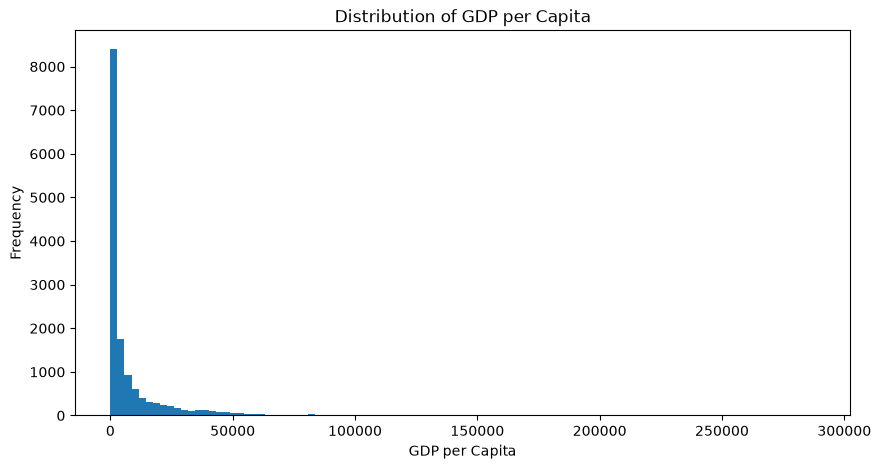

In [107]:
# Histogram for the Distributionof GDP per Capita
plt.figure(figsize=(10, 5))
plt.hist(gdp_clean['GDP_Per_Capita'], bins=100)
plt.title('Distribution of GDP per Capita')
plt.xlabel('GDP per Capita')
plt.ylabel('Frequency')
plt.show()

# Right skewed

In [108]:
# tourist_clean

# Identify the Q1,Q2,Q3 and Inter Quartile Range
Q1,Q2,Q3 = tourist_clean['Tourist Arrival'].quantile([0.25,0.5,0.75])
IQR = Q3 - Q1
lower,upper = Q1 - 1.5*IQR ,Q3 + 1.5*IQR

# Number of outliers
tourist_outliers = tourist_clean[(tourist_clean['Tourist Arrival'] < lower) | (tourist_clean['Tourist Arrival'] > upper)]

# Mean,median,Standard deviation
# Precenatage of outliers
print(f"Number of Outliers : {len(tourist_outliers)} \n\nMedian : {Q2:.2f} \nMean : {np.mean(tourist_clean['Tourist Arrival']):.2f} \nStandard Deviation : {np.std(tourist_clean['Tourist Arrival']):.2f} \n\nPrecentage of Outliers : {(len(tourist_outliers)/len(tourist_clean))*100:.2f}%")

tourist_outliers.reset_index(drop=True)

Number of Outliers : 766 

Median : 1756.00 
Mean : 8279.83 
Standard Deviation : 25979.97 

Precentage of Outliers : 13.27%


,date,Country,Tourist Arrival,unit,geography,status,source,Year
0,2011-01-01,All countries,74197,arrivals,LK,unflagged,sltda-asr-2011,2011
1,2011-02-01,All countries,65797,arrivals,LK,unflagged,sltda-asr-2011,2011
2,2011-03-01,All countries,75130,arrivals,LK,unflagged,sltda-asr-2011,2011
3,2011-04-01,All countries,63835,arrivals,LK,unflagged,sltda-asr-2011,2011
4,2011-05-01,All countries,48943,arrivals,LK,unflagged,sltda-asr-2011,2011
...,...,...,...,...,...,...,...,...
761,2026-03-01,United Kingdom,18092,arrivals,LK,subject to change,sltda-markets-2026,2026
762,2026-07-01,United Kingdom,21834,arrivals,LK,subject to change,sltda-markets-2026,2026
763,2026-08-01,United Kingdom,19588,arrivals,LK,subject to change,sltda-markets-2026,2026
764,2019-03-01,United States,12543,arrivals,LK,unflagged,sltda-markets-2019,2019


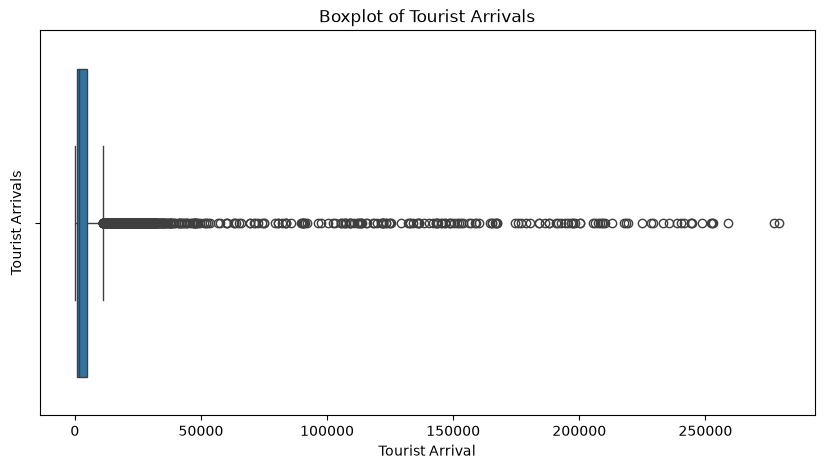

In [109]:
# Boxplots of tourist Arrivals
plt.figure(figsize=(10,5))
sns.boxplot(x=tourist_clean['Tourist Arrival'])
plt.title('Boxplot of Tourist Arrivals')
plt.ylabel('Tourist Arrivals')
plt.show()

# Right skewed distribution of tourist arrival

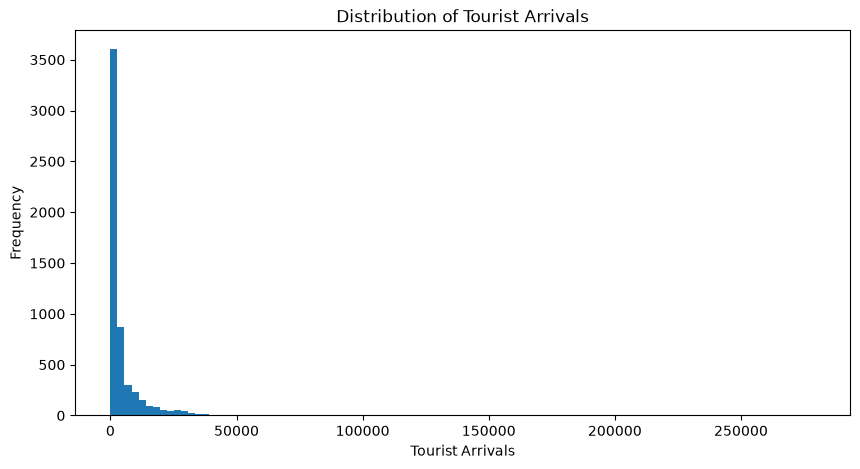

In [110]:
# Histograms Distribution of tourist arrival
plt.figure(figsize=(10, 5))
plt.hist(tourist_clean['Tourist Arrival'], bins=100)
plt.title('Distribution of Tourist Arrivals')
plt.xlabel('Tourist Arrivals')
plt.ylabel('Frequency')
plt.show()

# right skewed

In [111]:
# sorting gdp outliers using GDP_Per_Capita desecnding order after get first 25 rows
gdp_outliers[["Country", "Year", "GDP_Per_Capita"]].sort_values(by="GDP_Per_Capita", ascending=False).head(25)

,Country,Year,GDP_Per_Capita
8299,Monaco,2024,288001.433369
8298,Monaco,2023,256799.788613
8297,Monaco,2022,226052.001905
8296,Monaco,2021,223823.363960
7682,Liechtenstein,2023,206780.590353
8283,Monaco,2008,204263.797114
7680,Liechtenstein,2021,201944.830335
8289,Monaco,2014,195693.570739
8294,Monaco,2019,193746.785647
8293,Monaco,2018,188298.315668


In [112]:
# sorting tourist outliers using Tourist arrival desecnding order after get first 25 rows
tourist_outliers[["date", "Country", "Tourist Arrival"]].sort_values(by="Tourist Arrival", ascending=False).head(25)

,date,Country,Tourist Arrival
181,2026-02-01,All countries,279328
180,2026-01-01,All countries,277327
179,2025-12-01,All countries,258928
95,2018-12-01,All countries,253169
168,2025-01-01,All countries,252761
97,2019-02-01,All countries,252033
167,2024-12-01,All countries,248592
83,2017-12-01,All countries,244536
98,2019-03-01,All countries,244328
96,2019-01-01,All countries,244239


In [113]:
# copy of the GDP anf tourist
gdp_final = gdp_clean.copy()
tourist_final = tourist_clean.copy()

In [114]:
# Description of the Column names, Non Null values, Data types of GDP
gdp_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 14562 entries, 0 to 14561
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country         14562 non-null  str    
 1   Country Code    14562 non-null  str    
 2   Year            14562 non-null  int64  
 3   GDP_Per_Capita  14562 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 455.2 KB


In [115]:
# Description of the Column names, Non Null values, Data types of tourist
tourist_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 5772 entries, 0 to 5771
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             5772 non-null   datetime64[us]
 1   Country          5772 non-null   str           
 2   Tourist Arrival  5772 non-null   int64         
 3   unit             5772 non-null   str           
 4   geography        5772 non-null   str           
 5   status           5772 non-null   str           
 6   source           5772 non-null   str           
 7   Year             5772 non-null   int64         
dtypes: datetime64[us](1), int64(2), str(5)
memory usage: 360.9 KB


In [116]:
# GDP columns names
print("GDP columns:",gdp_clean.columns.tolist())

GDP columns: ['Country', 'Country Code', 'Year', 'GDP_Per_Capita']


In [117]:
# Tourisr columns names
print("Tourism columns:",tourist_clean.columns.tolist())

Tourism columns: ['date', 'Country', 'Tourist Arrival', 'unit', 'geography', 'status', 'source', 'Year']


## Data Integration

The cleaned GDP and tourist datasets were integrated using the Pandas `merge()` function.

An **INNER JOIN** was performed using the common columns `Country` and `Year`.

This method retains only the records that have matching country and year values in both datasets. The resulting dataset combines GDP per capita and tourist arrivals, allowing further analysis of the relationship between these two variables.

In [118]:
# Merge gdp clean and tourist clean using Country names and Year with inner join
merge_df = pd.merge(gdp_clean,tourist_clean,on=['Country','Year'],how='inner')
merge_df.head()

,Country,Country Code,Year,GDP_Per_Capita,date,Tourist Arrival,unit,geography,status,source
0,Australia,AUS,2011,62799.389502,2011-01-01,3588,arrivals,LK,unflagged,sltda-asr-2011
1,Australia,AUS,2011,62799.389502,2011-02-01,2223,arrivals,LK,unflagged,sltda-asr-2011
2,Australia,AUS,2011,62799.389502,2011-03-01,3017,arrivals,LK,unflagged,sltda-asr-2011
3,Australia,AUS,2011,62799.389502,2011-04-01,3341,arrivals,LK,unflagged,sltda-asr-2011
4,Australia,AUS,2011,62799.389502,2011-05-01,1764,arrivals,LK,unflagged,sltda-asr-2011


In [119]:
# Shape of the merge dataframe
merge_df.shape

(4476, 10)

In [120]:
# data types of merge dataframe
merge_df.dtypes

Country                       str
Country Code                  str
Year                        int64
GDP_Per_Capita            float64
date               datetime64[us]
Tourist Arrival             int64
unit                          str
geography                     str
status                        str
source                        str
dtype: object

In [121]:
# Summary of the merge dataframe
merge_df.describe()

,Year,GDP_Per_Capita,date,Tourist Arrival
count,4476.000000,4476.000000,4476,4476.000000
mean,2017.726542,41746.346466,2018-03-08 16:42:27.989276,3777.117069
min,2011.000000,1131.735138,2011-01-01 00:00:00,0.000000
25%,2014.000000,14889.018555,2014-11-01 00:00:00,636.000000
50%,2018.000000,44250.631363,2018-05-01 00:00:00,1589.000000
75%,2021.000000,55645.606861,2021-09-01 00:00:00,3935.500000
max,2024.000000,112894.953241,2024-12-01 00:00:00,52881.000000
std,3.985036,26023.200311,NaN,6039.326250


In [122]:
# Description of the Column names,Non null values and Data types
merge_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4476 entries, 0 to 4475
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Country          4476 non-null   str           
 1   Country Code     4476 non-null   str           
 2   Year             4476 non-null   int64         
 3   GDP_Per_Capita   4476 non-null   float64       
 4   date             4476 non-null   datetime64[us]
 5   Tourist Arrival  4476 non-null   int64         
 6   unit             4476 non-null   str           
 7   geography        4476 non-null   str           
 8   status           4476 non-null   str           
 9   source           4476 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(2), str(6)
memory usage: 349.8 KB


In [123]:
# Finding the missing values
merge_df.isnull().sum()

Country            0
Country Code       0
Year               0
GDP_Per_Capita     0
date               0
Tourist Arrival    0
unit               0
geography          0
status             0
source             0
dtype: int64

In [124]:
# Find any duplicates in merge dataframe
merge_df.duplicated().sum()

np.int64(0)

In [125]:
# Number of records and shape in the GDP,Tourist and merge dataframe
print(f"GDP records : {len(gdp_clean)} \nGDP Shape : {gdp_clean.shape}\n")
print(f"Tourism records : {len(tourist_clean)} \nTourist Shape : {tourist_clean.shape}\n")
print(f"Merged records : {len(merge_df)} \nMerged Shape : {merge_df.shape}")

GDP records : 14562 
GDP Shape : (14562, 4)

Tourism records : 5772 
Tourist Shape : (5772, 8)

Merged records : 4476 
Merged Shape : (4476, 10)


In [126]:
# Number of unique countries
print("Unique countries:", merge_df["Country"].nunique())

Unique countries: 28


In [127]:
# Value counts for the Country
merge_df['Country'].value_counts().sort_values(ascending=False)

Country
Australia             168
Austria               168
Belgium               168
Canada                168
Switzerland           168
China                 168
Germany               168
Denmark               168
Spain                 168
France                168
United Kingdom        168
India                 168
Italy                 168
Japan                 168
Maldives              168
Malaysia              168
Netherlands           168
Norway                168
New Zealand           168
Pakistan              168
Russian Federation    168
Singapore             168
Sweden                168
United States         168
Bangladesh            120
Israel                120
Poland                120
Ireland                84
Name: count, dtype: int64

In [128]:
# Unique country names
merge_df['Country'].unique()

<StringArray>
[         'Australia',            'Austria',            'Belgium',
         'Bangladesh',             'Canada',        'Switzerland',
              'China',            'Germany',            'Denmark',
              'Spain',             'France',     'United Kingdom',
              'India',            'Ireland',             'Israel',
              'Italy',              'Japan',           'Maldives',
           'Malaysia',        'Netherlands',             'Norway',
        'New Zealand',           'Pakistan',             'Poland',
 'Russian Federation',          'Singapore',             'Sweden',
      'United States']
Length: 28, dtype: str

In [129]:
# Number of unique year
print("Unique years:", merge_df["Year"].nunique())

Unique years: 14


In [130]:
# unique years
merge_df['Year'].unique()

array([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021,
       2022, 2023, 2024])

In [131]:
# number data type columns name
merge_df.select_dtypes(include=['number']).columns

Index(['Year', 'GDP_Per_Capita', 'Tourist Arrival'], dtype='str')

In [132]:
# object data type columns name
merge_df.select_dtypes(include=['object']).columns

C:\Users\pc\AppData\Local\Temp\ipykernel_22988\4022438467.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  merge_df.select_dtypes(include=['object']).columns


Index(['Country', 'Country Code', 'unit', 'geography', 'status', 'source'],
      dtype='str')

In [133]:
# Summary for the number data type
merge_df.describe(include='number')

,Year,GDP_Per_Capita,Tourist Arrival
count,4476.000000,4476.000000,4476.000000
mean,2017.726542,41746.346466,3777.117069
std,3.985036,26023.200311,6039.326250
min,2011.000000,1131.735138,0.000000
25%,2014.000000,14889.018555,636.000000
50%,2018.000000,44250.631363,1589.000000
75%,2021.000000,55645.606861,3935.500000
max,2024.000000,112894.953241,52881.000000


In [134]:
# select the object type of data
merge_df.select_dtypes(include=['object']).head()

C:\Users\pc\AppData\Local\Temp\ipykernel_22988\1530559675.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  merge_df.select_dtypes(include=['object']).head()


,Country,Country Code,unit,geography,status,source
0,Australia,AUS,arrivals,LK,unflagged,sltda-asr-2011
1,Australia,AUS,arrivals,LK,unflagged,sltda-asr-2011
2,Australia,AUS,arrivals,LK,unflagged,sltda-asr-2011
3,Australia,AUS,arrivals,LK,unflagged,sltda-asr-2011
4,Australia,AUS,arrivals,LK,unflagged,sltda-asr-2011


# Data Standardization

Standardization was performed using the StandardScaler function from Scikit-learn.

The GDP per capita and tourist-arrival variables were standardized to have a mean of approximately zero and a standard deviation of approximately one.

The standardized values were stored in separate columns, preserving the original numerical values.

In [135]:
# Standardization:
# StandardScaler is used to transform numerical features
# (GDP per capita and tourist arrivals) to a common scale
scaler = StandardScaler()
merge_df[['Scaled GDP', 'Scaled Tourist Arrival']] = scaler.fit_transform(merge_df[['GDP_Per_Capita', 'Tourist Arrival']])

In [136]:
# Display the final dataset structure
merge_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4476 entries, 0 to 4475
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Country                 4476 non-null   str           
 1   Country Code            4476 non-null   str           
 2   Year                    4476 non-null   int64         
 3   GDP_Per_Capita          4476 non-null   float64       
 4   date                    4476 non-null   datetime64[us]
 5   Tourist Arrival         4476 non-null   int64         
 6   unit                    4476 non-null   str           
 7   geography               4476 non-null   str           
 8   status                  4476 non-null   str           
 9   source                  4476 non-null   str           
 10  Scaled GDP              4476 non-null   float64       
 11  Scaled Tourist Arrival  4476 non-null   float64       
dtypes: datetime64[us](1), float64(3), int64(2), str(6)
memory u

In [137]:
# Display the first five records of the final dataset
merge_df.head()

,Country,Country Code,Year,GDP_Per_Capita,date,Tourist Arrival,unit,geography,status,source,Scaled GDP,Scaled Tourist Arrival
0,Australia,AUS,2011,62799.389502,2011-01-01,3588,arrivals,LK,unflagged,sltda-asr-2011,0.809101,-0.031318
1,Australia,AUS,2011,62799.389502,2011-02-01,2223,arrivals,LK,unflagged,sltda-asr-2011,0.809101,-0.257362
2,Australia,AUS,2011,62799.389502,2011-03-01,3017,arrivals,LK,unflagged,sltda-asr-2011,0.809101,-0.125875
3,Australia,AUS,2011,62799.389502,2011-04-01,3341,arrivals,LK,unflagged,sltda-asr-2011,0.809101,-0.072221
4,Australia,AUS,2011,62799.389502,2011-05-01,1764,arrivals,LK,unflagged,sltda-asr-2011,0.809101,-0.333372


In [138]:
os.makedirs("Cleaned_Data",exist_ok=True)

In [139]:
# Save the cleaned GDP dataset
gdp_clean.to_csv('Cleaned_Data/GDP_Cleaned.csv', index=False)

In [140]:
# Save the cleaned Tourism dataset
tourist_clean.to_csv('Cleaned_Data/Tourism_Cleaned.csv', index=False)

In [141]:
# Save the final merged dataset
merge_df.to_csv('Cleaned_Data/GDP_Tourism_Cleaned.csv', index=False)

# Visualizations
* Bar Chart: Compare tourist arrivals between countries.
* Time Series Plot: Examine monthly tourist-arrival trends over time.
* Scatter Plot: Explore the relationship between GDP per capita and tourist arrivals.
* Histogram: Understand numerical data distributions.
* Box Plot: Identify potential outliers.

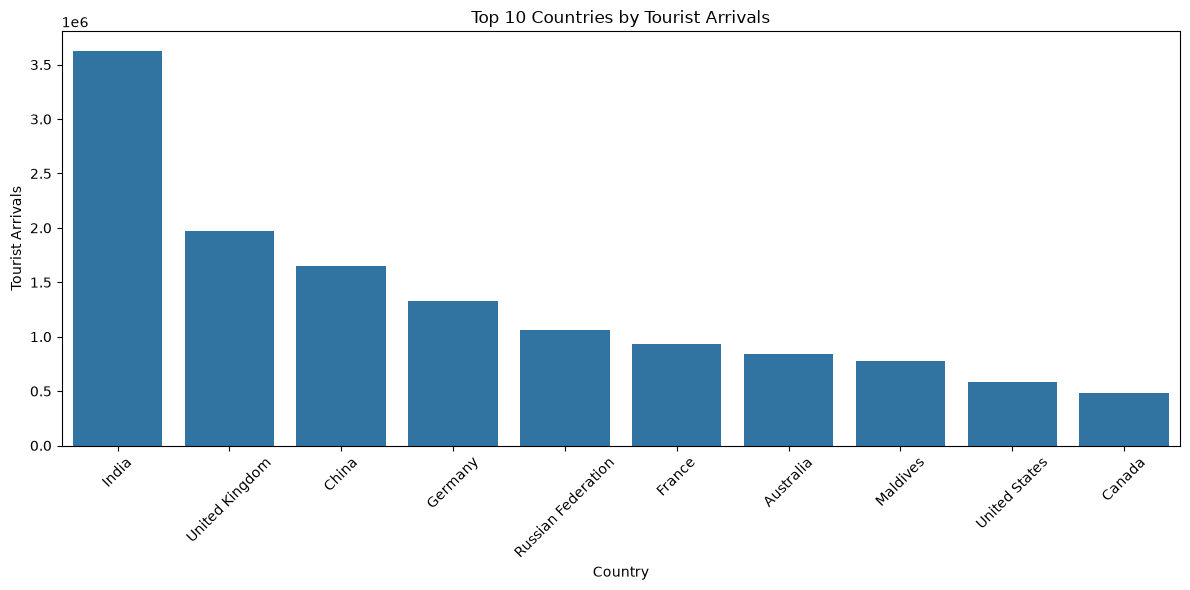

In [142]:
# Compare tourist arrivals between countries
country_arrivals = merge_df.groupby('Country')['Tourist Arrival'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=country_arrivals.index, y=country_arrivals.values)
plt.title('Top 10 Countries by Tourist Arrivals')
plt.xlabel('Country')
plt.ylabel('Tourist Arrivals')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

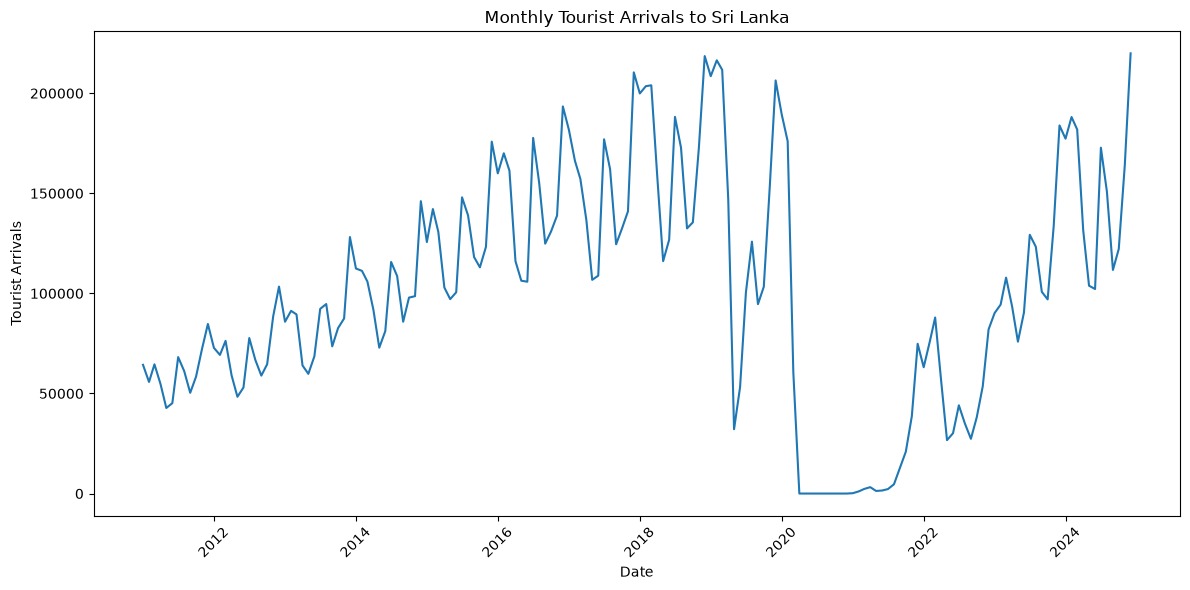

In [143]:
# Examine monthly tourist-arrival trends over time
monthly_arrivals = merge_df.groupby('date')['Tourist Arrival'].sum().sort_index()

plt.figure(figsize=(12, 6))
plt.plot(monthly_arrivals.index, monthly_arrivals.values)
plt.title('Monthly Tourist Arrivals to Sri Lanka')
plt.xlabel('Date')
plt.ylabel('Tourist Arrivals')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Irregular fluctuation 2019 to 2022,affect the covid 19

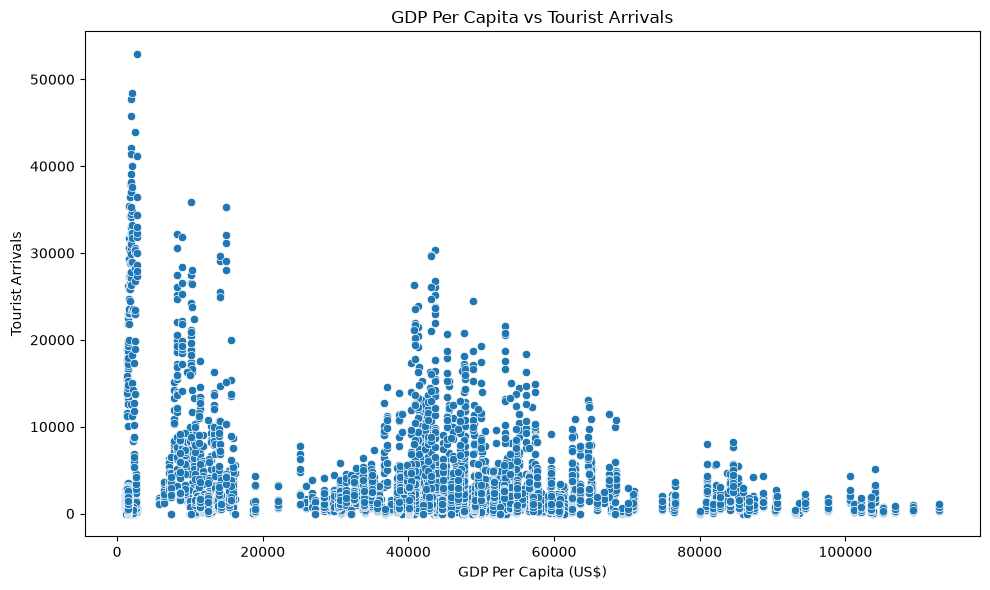

In [144]:
# Explore the relationship between GDP per capita and tourist arrivals

plt.figure(figsize=(10, 6))
sns.scatterplot(data=merge_df, x='GDP_Per_Capita', y='Tourist Arrival')
plt.title('GDP Per Capita vs Tourist Arrivals')
plt.xlabel('GDP Per Capita (US$)')
plt.ylabel('Tourist Arrivals')
plt.tight_layout()
plt.show()